In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

E:\Other\MU25\mu25-ml-group-2\.pixi\envs\default\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Set the path to the file you'd like to load
file_path = "traffic_flow_sensors.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "olaflundstrom/nordcauc-urban-mobility-intelligence",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

#df["congestion_level"] = df["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]

df.drop(columns=['next_timestamp', 'duration_to_next'])

C:\Users\Simon\AppData\Local\Temp\ipykernel_17772\1325916167.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,temperature_c,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag,future_congestion_level,next_sensor_id
162,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-05-28 20:45:00,2023-05-28,20,Sunday,True,False,...,30.8,0.5,light_rain,none,124,moderate,NordFlow-GNN,good,moderate,STO-NOR-0001
311,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-09-21 13:45:00,2023-09-21,13,Thursday,False,False,...,12.5,2.2,light_rain,none,18,free_flow,NordFlow-GNN,good,free_flow,STO-NOR-0001
419,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-01-10 17:30:00,2024-01-10,17,Wednesday,False,False,...,0.4,0.0,sleet,none,211,heavy,NordFlow-GNN,good,heavy,STO-NOR-0001
505,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-03-22 00:15:00,2024-03-22,0,Friday,False,False,...,13.0,0.0,partly_cloudy,none,19,free_flow,NordFlow-GNN,good,free_flow,STO-NOR-0001
558,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-04-29 14:30:00,2024-04-29,14,Monday,False,False,...,27.2,2.4,drizzle,none,23,free_flow,NordFlow-GNN,good,free_flow,STO-NOR-0001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199351,BAK-KHA-0160,Baku,Azerbaijan,Khatai,2023-12-24 09:30:00,2023-12-24,9,Sunday,True,False,...,7.7,0.3,light_rain,none,901,moderate,SmartArt-Transformer,good,moderate,BAK-KHA-0160
199487,BAK-KHA-0160,Baku,Azerbaijan,Khatai,2024-04-24 11:15:00,2024-04-24,11,Wednesday,False,False,...,28.0,0.6,light_rain,none,236,free_flow,SmartArt-Transformer,good,free_flow,BAK-KHA-0160
199570,BAK-KHA-0160,Baku,Azerbaijan,Khatai,2024-07-11 19:15:00,2024-07-11,19,Thursday,False,False,...,34.1,0.2,light_rain,none,652,light,SmartArt-Transformer,good,free_flow,BAK-KHA-0160
199699,BAK-KHA-0160,Baku,Azerbaijan,Khatai,2024-11-06 23:00:00,2024-11-06,23,Wednesday,False,False,...,12.1,1.3,drizzle,none,153,free_flow,SmartArt-Transformer,good,free_flow,BAK-KHA-0160


In [60]:
df_processed = df[df["data_quality_flag"] == "good"]
df_processed = df_processed.drop(columns=["sensor_id", "city", "country", "district", "timestamp", "date", "latitude", "longitude", "ev_count_15min", "ai_predicted_volume", "ai_predicted_congestion", "ai_model_version", "data_quality_flag"])

In [61]:
x = df_processed.drop(columns=["future_congestion_level"])
y = df_processed["future_congestion_level"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [62]:
base_line = DummyClassifier(strategy="most_frequent").fit(x_train, y_train)
accuracy_score(y_test, base_line.predict(x_test))

0.47101449275362317

In [63]:
df_processed.info()

<class 'pandas.DataFrame'>
Index: 2070 entries, 162 to 199953
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype          
---  ------                   --------------  -----          
 0   hour                     2070 non-null   int64          
 1   day_of_week              2070 non-null   str            
 2   is_weekend               2070 non-null   bool           
 3   is_public_holiday        2070 non-null   bool           
 4   season                   2070 non-null   str            
 5   road_type                2070 non-null   str            
 6   speed_limit_kmh          2070 non-null   int64          
 7   lane_count               2070 non-null   int64          
 8   vehicle_count_15min      2070 non-null   int64          
 9   avg_speed_kmh            2070 non-null   float64        
 10  congestion_level         2070 non-null   str            
 11  occupancy_rate           2070 non-null   float64        
 12  truck_count_15min        2070 no

In [65]:
df_processed["future_congestion_level"] = df_processed["future_congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

<class 'pandas.DataFrame'>
Index: 2070 entries, 162 to 199953
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype          
---  ------                   --------------  -----          
 0   hour                     2070 non-null   int64          
 1   day_of_week              2070 non-null   str            
 2   is_weekend               2070 non-null   bool           
 3   is_public_holiday        2070 non-null   bool           
 4   season                   2070 non-null   str            
 5   road_type                2070 non-null   str            
 6   speed_limit_kmh          2070 non-null   int64          
 7   lane_count               2070 non-null   int64          
 8   vehicle_count_15min      2070 non-null   int64          
 9   avg_speed_kmh            2070 non-null   float64        
 10  congestion_level         2070 non-null   str            
 11  occupancy_rate           2070 non-null   float64        
 12  truck_count_15min        2070 no

<Axes: >

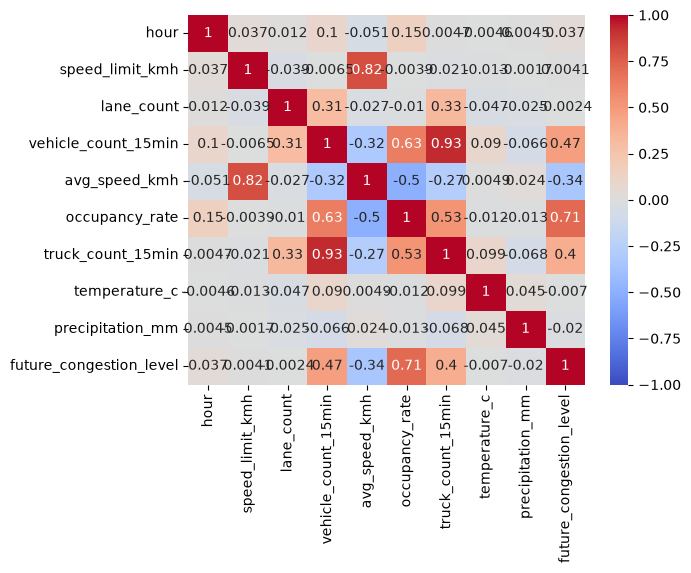

In [66]:
df_clean = df_processed.dropna()
numeric_df = df_clean.select_dtypes(include=['float64','int64'])
print(df_processed.info())
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, cmap='coolwarm')

In [67]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(x_train[["occupancy_rate"]], y_train)
accuracy_score(y_test, tree.predict(x_test[["occupancy_rate"]]))

0.6763285024154589